<a href="https://colab.research.google.com/github/Jahura7/Mammographic_Mass_Classification_with_a_Decision_Tree/blob/experiment.ipynb/Mammographic_Mass_Classification_with_a_Decision_Tree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **1. Import Libraries and Set Reproducibility**

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    RocCurveDisplay,
)

In [4]:
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV,
    cross_validate,
)

In [5]:
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree

RANDOM_STATE = 42
TEST_SIZE = 0.20

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# **2. Load and Validate the data**

In [6]:
df = pd.read_csv("mammographic_masses_data_clean.csv")

In [7]:
df.head()

,BI-RADS,Age,Shape,Margin,Density,Target
0,5,67,3,5,3,1
1,5,58,4,5,3,1
2,4,28,1,1,3,0
3,5,57,1,5,3,1
4,5,76,1,4,3,1


In [8]:
df.tail()

,BI-RADS,Age,Shape,Margin,Density,Target
825,4,47,2,1,3,0
826,4,56,4,5,3,1
827,4,64,4,5,3,0
828,5,66,4,5,3,1
829,4,62,3,3,3,0


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 830 entries, 0 to 829
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   BI-RADS  830 non-null    int64
 1   Age      830 non-null    int64
 2   Shape    830 non-null    int64
 3   Margin   830 non-null    int64
 4   Density  830 non-null    int64
 5   Target   830 non-null    int64
dtypes: int64(6)
memory usage: 39.0 KB


In [13]:
df.shape

(830, 6)

In [14]:
df.dtypes

,0
BI-RADS,int64
Age,int64
Shape,int64
Margin,int64
Density,int64
Target,int64


In [15]:
df.isna().sum().to_frame("missing_values")

,missing_values
BI-RADS,0
Age,0
Shape,0
Margin,0
Density,0
Target,0


In [16]:
df.duplicated().sum()

np.int64(266)

In [17]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
BI-RADS,830.0,4.393976,1.888371,0.0,4.0,4.0,5.0,55.0
Age,830.0,55.781928,14.671782,18.0,46.0,57.0,66.0,96.0
Shape,830.0,2.781928,1.242361,1.0,2.0,3.0,4.0,4.0
Margin,830.0,2.813253,1.567175,1.0,1.0,3.0,4.0,5.0
Density,830.0,2.915663,0.350936,1.0,3.0,3.0,3.0,4.0
Target,830.0,0.485542,0.500092,0.0,0.0,0.0,1.0,1.0


In [18]:
df["Target"].value_counts(dropna=False).sort_index().to_frame("count")

,count
Target,
0,427
1,403


**Data Validation before trainning**

In [19]:
# step1 : Define the feature columns and Target columns

feature_columns = ["BI-RADS", "Age", "Shape", "Margin", "Density"]
target_column = "Target"

In [20]:
# Step 2: Convert columns to numeric values

for column in feature_columns + [target_column]:
    df[column] = pd.to_numeric(df[column], errors="coerce")

In [21]:
# Step 3: Check for missing target values

if df[target_column].isna().any():
    raise ValueError(
        "Target contains missing or non-numeric values; investigate before modelling."
    )

In [22]:
# Step 4: Check that the target is binary

target_values = set(df[target_column].unique())

In [23]:
# Step 5: Verify target contains exactly 0 and 1

if not target_values.issubset({0, 1}) or len(target_values) != 2:
    raise ValueError(
        f"Expected a binary target coded 0/1; found {sorted(target_values)}."
    )

**Define X and y**

In [24]:
X = df[feature_columns]
y = df[target_column].astype(int)

print("Features:", feature_columns)
print("Target labels:", sorted(y.unique()))
print("Target proportions:")
display(y.value_counts(normalize=True).sort_index().rename("proportion").to_frame())

Features: ['BI-RADS', 'Age', 'Shape', 'Margin', 'Density']
Target labels: [np.int64(0), np.int64(1)]
Target proportions:


,proportion
Target,
0,0.514458
1,0.485542


# **3. Explore the Data**

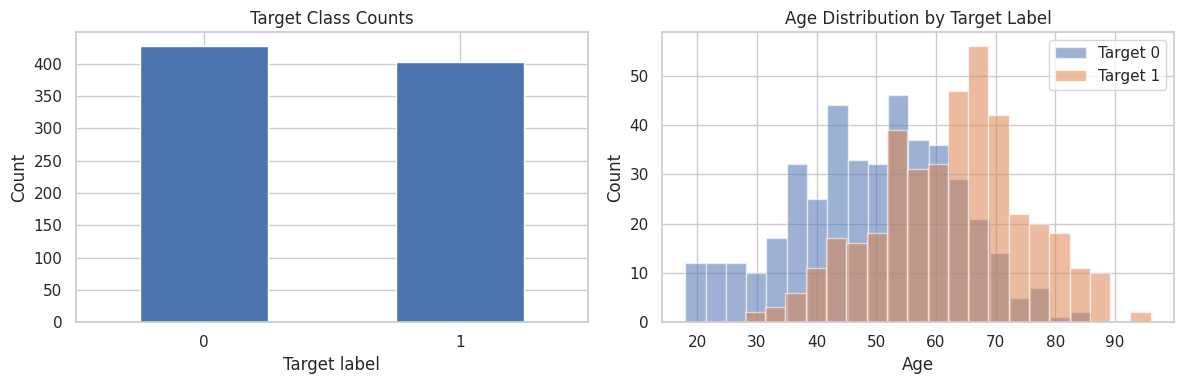

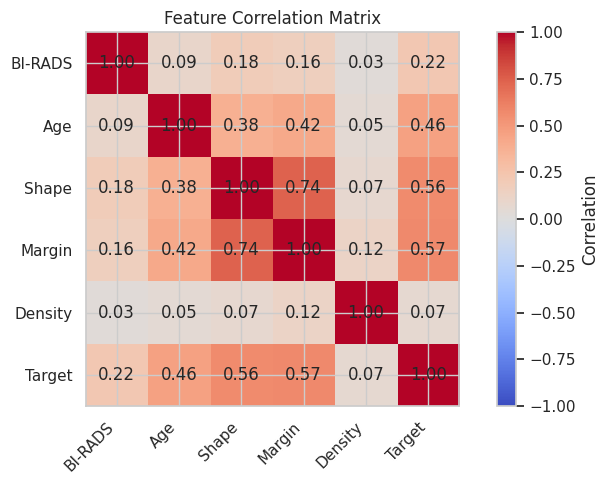

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df["Target"].value_counts().sort_index().plot(kind="bar", ax=axes[0])
axes[0].set_title("Target Class Counts")
axes[0].set_xlabel("Target label")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis="x", rotation=0)

for label in sorted(df["Target"].unique()):
    axes[1].hist(df.loc[df["Target"] == label, "Age"], bins=20, alpha=0.55, label=f"Target {label}")
axes[1].set_title("Age Distribution by Target Label")
axes[1].set_xlabel("Age")
axes[1].set_ylabel("Count")
axes[1].legend()

plt.tight_layout()
plt.show()

corr = df[feature_columns + [target_column]].corr()
fig, ax = plt.subplots(figsize=(8, 5))
image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)), labels=corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr.index)), labels=corr.index)
for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
fig.colorbar(image, ax=ax, label="Correlation")
ax.set_title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

**EDA Findings:**

* The dataset contains 830 records and six columns.



* The target classes are reasonably balanced: 427 records in class 0 and 403 in class 1.



* Class 1 has a higher mean age than class 0.



* Shape and Margin: These features are strongly associated with each other, meaning their encoded values tend to vary together.



* Margin and Shape with Target: Both show stronger correlations with the target than Density does.



* Age: Shows a moderate positive association with the target codes.



* Density: Has very little linear correlation with the target codes in this dataset.

# **4. Create a stratified train/test split**

The test set is held out until the final evaluation. Stratification helps preserve the target-class proportions in both sets. All model selection and cross-validation happen using the training set only.

In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Training set: {X_train.shape[0]} rows")
print(f"Test set:     {X_test.shape[0]} rows")

Training set: 664 rows
Test set:     166 rows


In [27]:
split_summary = pd.DataFrame({
    "Full dataset": y.value_counts(normalize=True).sort_index(),
    "Training set": y_train.value_counts(normalize=True).sort_index(),
    "Test set": y_test.value_counts(normalize=True).sort_index(),
}).rename_axis("Target label")
display(split_summary)

,Full dataset,Training set,Test set
Target label,,,
0,0.514458,0.51506,0.512048
1,0.485542,0.48494,0.487952


# **5. Establish a simple baseline**

A dummy classifier provides a reference point. A useful model should outperform this baseline on relevant metrics, not just report a seemingly high accuracy.

In [28]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

baseline_results = {
    "Model": "Most-frequent baseline",
    "Accuracy": accuracy_score(y_test, baseline_pred),
    "Balanced accuracy": balanced_accuracy_score(y_test, baseline_pred),
    "Precision (label 1)": precision_score(y_test, baseline_pred, pos_label=1, zero_division=0),
    "Recall (label 1)": recall_score(y_test, baseline_pred, pos_label=1, zero_division=0),
    "F1 (label 1)": f1_score(y_test, baseline_pred, pos_label=1, zero_division=0),
}
display(pd.DataFrame([baseline_results]).set_index("Model"))

,Accuracy,Balanced accuracy,Precision (label 1),Recall (label 1),F1 (label 1)
Model,,,,,
Most-frequent baseline,0.512048,0.5,0.0,0.0,0.0
